# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Setup
Install the libraries once before running the lesson and tasks. Word IDs, padding, and tensors are prepared directly with Python and PyTorch.

In [ ]:
%pip install -q pandas torch matplotlib

## Step 1 — Import libraries

In [2]:
from pathlib import Path
import re
import pandas as pd
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence
import matplotlib.pyplot as plt

torch.manual_seed(42)
torch.set_num_threads(2)

## Step 2 — Load the dataset
The course Q&A dataset is included in the `dataset` folder beside this notebook.

In [3]:
dataset_path = Path("dataset/Lab_11_QnA_Dataset.csv")
df = pd.read_csv(dataset_path)
required_columns = ["question", "answer_id", "answer"]
if df[required_columns].isna().any().any():
    raise ValueError("Questions, answer IDs, and answers must not be missing.")
if (df.groupby("answer_id")["answer"].nunique() != 1).any():
    raise ValueError("Each answer ID must identify exactly one answer.")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
df.head()

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [4]:
def tokenize_question(question):
    cleaned = re.sub(r"[^\w\s]", "", question.lower())
    return cleaned.split()

# Keep the original text for display; use identical tokens in the model and charts.
question_tokens = [tokenize_question(question) for question in df["question"]]
if any(not tokens for tokens in question_tokens):
    raise ValueError("Every question must contain at least one word.")
word_to_id = {word: index + 1 for index, word in enumerate(sorted({
    word for tokens in question_tokens for word in tokens
}))}
question_sequences = [
    torch.tensor([word_to_id[word] for word in tokens], dtype=torch.long)
    for tokens in question_tokens
]
X = pad_sequence(question_sequences, batch_first=True, padding_value=0)
answer_ids = sorted(df["answer_id"].unique().tolist())
answer_to_class = {answer_id: index for index, answer_id in enumerate(answer_ids)}
y = torch.tensor([answer_to_class[value] for value in df["answer_id"]], dtype=torch.long)
print("Padded question tensor:", tuple(X.shape))
print("Vocabulary size:", len(word_to_id))

Padded question tensor: (168, 11)
Vocabulary size: 226


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [5]:
class AttentionRNN(nn.Module):
    def __init__(self, vocabulary_size, number_of_answers):
        super().__init__()
        self.emb = nn.Embedding(vocabulary_size, 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, number_of_answers)

    def forward(self, x):
        mask = x != 0
        if not mask.any(dim=1).all():
            raise ValueError("An input question contains only padding.")
        hidden_states, _ = self.rnn(self.emb(x))
        scores = self.att(hidden_states).squeeze(-1)
        scores = scores.masked_fill(~mask, float("-inf"))
        weights = torch.softmax(scores, dim=1)
        context = (hidden_states * weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(context), weights

model = AttentionRNN(len(word_to_id) + 1, len(answer_ids))
print(model)

AttentionRNN(
  (emb): Embedding(227, 16, padding_idx=0)
  (rnn): RNN(16, 32, batch_first=True)
  (att): Linear(in_features=32, out_features=1, bias=True)
  (fc): Linear(in_features=32, out_features=12, bias=True)
)


## Step 5 — Train the model
The model learns which answer belongs to each question.

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
training_losses = []
for epoch in range(50):
    model.train()
    optimizer.zero_grad()
    logits, weights = model(X)
    loss = nn.functional.cross_entropy(logits, y)
    loss.backward()
    optimizer.step()
    training_losses.append(loss.item())
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1}/50 - Loss: {loss.item():.4f}")

model.eval()
with torch.no_grad():
    training_predictions = model(X)[0].argmax(dim=1)
training_accuracy = (training_predictions == y).float().mean().item()
print(f"Training accuracy: {training_accuracy:.1%}")
print("This measures fitting the supplied questions, not accuracy on unseen questions.")

Epoch 10/50 - Loss: 1.8904
Epoch 20/50 - Loss: 1.0504
Epoch 30/50 - Loss: 0.4775
Epoch 40/50 - Loss: 0.1759
Epoch 50/50 - Loss: 0.0608
Training accuracy: 99.4%
This measures fitting the supplied questions, not accuracy on unseen questions.


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

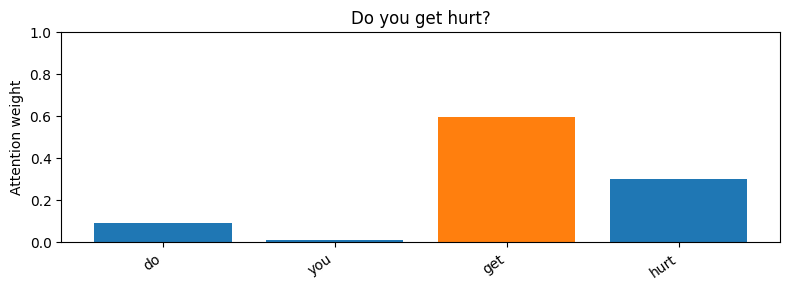

In [7]:
def attention_for_question(index):
    tokens = question_tokens[index]
    model.eval()
    with torch.no_grad():
        logits, attention_weights = model(X[index:index + 1])
    valid_weights = attention_weights[0, :len(tokens)].cpu().tolist()
    predicted_class = logits.argmax(dim=1).item()
    predicted_answer_id = answer_ids[predicted_class]
    answer = df.loc[df["answer_id"] == predicted_answer_id, "answer"].iloc[0]
    return tokens, valid_weights, answer

def plot_question_attention(index, ax):
    tokens, weights, answer = attention_for_question(index)
    strongest_position = max(range(len(weights)), key=weights.__getitem__)
    colors = ["tab:orange" if i == strongest_position else "tab:blue" for i in range(len(tokens))]
    ax.bar(range(len(tokens)), weights, color=colors)
    ax.set_xticks(range(len(tokens)), tokens, rotation=35, ha="right")
    ax.set_ylabel("Attention weight")
    ax.set_ylim(0, 1)
    ax.set_title(df.iloc[index]["question"])
    return {
        "Question": df.iloc[index]["question"],
        "Highest-attention word": tokens[strongest_position],
        "Attention weight": weights[strongest_position],
        "Predicted answer": answer,
    }

fig, ax = plt.subplots(figsize=(8, 3))
plot_question_attention(0, ax)
fig.tight_layout()
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

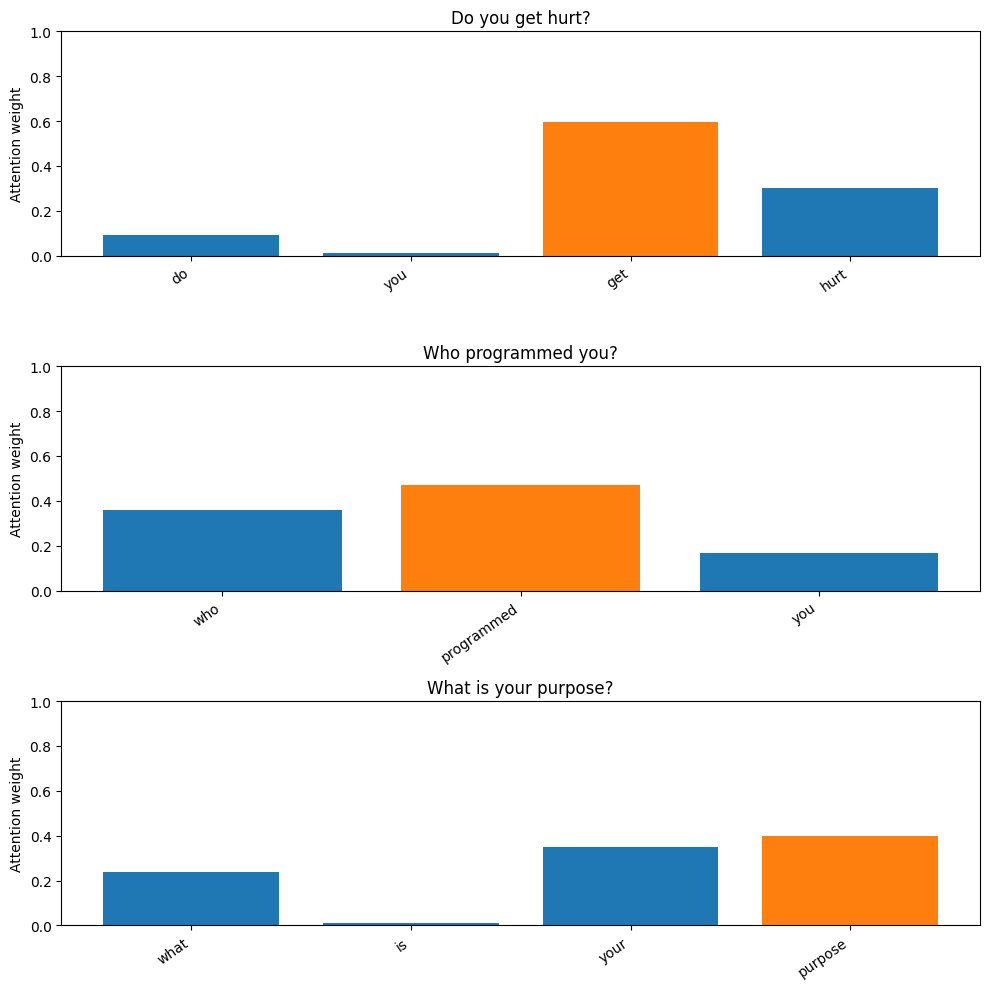

,Question,Highest-attention word,Attention weight,Predicted answer
0,Do you get hurt?,get,0.597200,I don't have a body.
1,Who programmed you?,programmed,0.470632,People created me.
2,What is your purpose?,purpose,0.400222,I'm here to answer your questions and help out.


In [8]:
selected_questions = [
    "Do you get hurt?",
    "Who programmed you?",
    "What is your purpose?",
]
selected_indices = [
    df.index[df["question"] == question][0]
    for question in selected_questions
]
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
task1_rows = [plot_question_attention(index, ax) for index, ax in zip(selected_indices, axes)]
fig.tight_layout()
plt.show()
task1_results = pd.DataFrame(task1_rows)
task1_results

### Task 1 observations
In the recorded run:

- **Do you get hurt?**: highest attention on **get** (0.597).
- **Who programmed you?**: highest attention on **programmed** (0.471).
- **What is your purpose?**: highest attention on **purpose** (0.400).

“Programmed” and “purpose” directly relate to what those questions ask. In the first question, “get” receives more attention than the more specific word “hurt”, so the strongest weight does not always select the word a human would consider most informative. Each RNN hidden state contains preceding context as well as information about its current token. These are learned attention patterns, not proof that a word caused the prediction.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

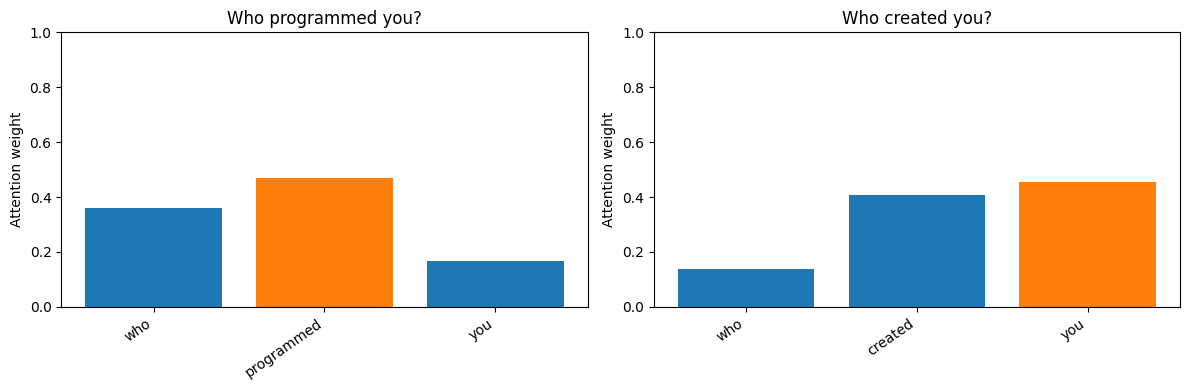

,Question,Highest-attention word,Attention weight,Predicted answer
0,Who programmed you?,programmed,0.470632,People created me.
1,Who created you?,you,0.454741,People created me.


In [9]:
similar_questions = ["Who programmed you?", "Who created you?"]
similar_indices = [
    df.index[df["question"] == question][0]
    for question in similar_questions
]
# Both questions refer to the creator and share the same answer group.
assert df.loc[similar_indices, "answer_id"].nunique() == 1
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
task2_rows = [plot_question_attention(index, ax) for index, ax in zip(similar_indices, axes)]
fig.tight_layout()
plt.show()
task2_results = pd.DataFrame(task2_rows)
task2_results

### Task 2 observations
For “Who programmed you?”, the highest-attention word is **programmed** (0.471). For “Who created you?”, it is **you** (0.455). Both receive the same predicted answer: **People created me.**

The model therefore emphasizes different positions for questions with similar meanings. The hidden state at “you” also encodes the preceding word “created”, so the bar does not measure that pronoun in isolation. Attention depends on the full sequence and the patterns learned during training; semantically similar questions do not have to produce matching word-level weights. These observations use training questions and do not establish performance on unseen paraphrases.